# 10 — Interpretabilidad del modelo seleccionado
## Pipeline CAD-TBX11K | Interpretabilidad del clasificador

Este notebook interpreta el modelo elegido por la CV del notebook 08. Lee el
modelo, el selector y el esquema de features desde los artefactos; no asume
XGBoost ni un selector concreto.

- Coeficientes estandarizados por clase para modelos lineales.
- Mapa de coeficientes HOG por bloque.
- Ejemplos OOF con contribuciones por feature.
- Oclusión 8×8 con relleno por mediana y referencia de azar.

---


In [30]:
import json
import os
import sys
import tempfile
from pathlib import Path

import cv2
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Rectangle

_CWD = Path.cwd()
PROJECT_ROOT = str(_CWD.parent if _CWD.name == 'notebooks' else _CWD)
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.features import extract_features, get_feature_groups, model_feature_columns
from src.preprocessing import preprocess
from src.visualization import set_publication_style

DATA_DIR = Path(PROJECT_ROOT) / 'data'
MODELS_DIR = Path(PROJECT_ROOT) / 'models'
REPORTS_DIR = Path(PROJECT_ROOT) / 'reports'
REPORTS_DIR.mkdir(exist_ok=True)
set_publication_style()


In [31]:
manifest = json.loads((MODELS_DIR / '08_manifest.json').read_text(encoding='utf-8'))
schema = json.loads((MODELS_DIR / '08_feature_schema.json').read_text(encoding='utf-8'))
seleccionado = manifest['seleccionado_cv']
modelo = joblib.load(MODELS_DIR / manifest['modelos'][seleccionado])

pasos = modelo.named_steps
selector = pasos['selector']
scaler = pasos.get('scaler')
clf = pasos['clf']
if not hasattr(clf, 'coef_'):
    print(
        f'El modelo seleccionado ({seleccionado}) no es lineal; '
        'se usa Logistic Regression como modelo lineal de referencia.'
    )
    seleccionado = 'Logistic Regression'
    modelo = joblib.load(MODELS_DIR / manifest['modelos'][seleccionado])
    pasos = modelo.named_steps
    selector = pasos['selector']
    scaler = pasos.get('scaler')
    clf = pasos['clf']

features_header = pd.read_csv(DATA_DIR / 'features_tbx11k.csv', nrows=0)
feat_cols = model_feature_columns(features_header)
sel_idx = selector.get_support(indices=True)
sel_names = [feat_cols[i] for i in sel_idx]

X_full = np.load(DATA_DIR / 'X_full.npy')
y_full = np.load(DATA_DIR / 'y_full.npy')
meta = pd.read_csv(DATA_DIR / 'full_meta.csv')
oof = pd.read_csv(DATA_DIR / '08_oof_predicciones.csv')

clases = clf.classes_.tolist()
idx_tb = int(np.where(clf.classes_ == 2)[0][0])
print('Modelo seleccionado:', seleccionado)
print('Selector:', schema['selector'])
print('Clases:', clases)
print('Features del modelo:', len(feat_cols), '| seleccionadas:', len(sel_names))


Modelo seleccionado: Logistic Regression
Selector: {'metodo': 'RF', 'n_features': 300}
Clases: [0, 1, 2]
Features del modelo: 1832 | seleccionadas: 300


## 1. Coeficientes estandarizados


,feature,mean_abs,health,sick,tb,familia
0,gabor_f0.3_t135_mean,0.7620,-0.9437,-0.1994,1.1431,texture
1,glcm_homogeneity_mean,0.7133,-1.0700,0.0158,1.0542,texture
2,gabor_f0.3_t45_mean,0.6937,-0.7302,-0.3104,1.0405,texture
3,glcm_correlation_mean,0.6124,-0.6064,-0.3122,0.9185,texture
4,glcm_energy_mean,0.4942,0.4989,0.2423,-0.7413,texture
5,gabor_f0.1_t0_mean,0.4546,-0.2580,0.6819,-0.4238,texture
6,glcm_contrast_mean,0.4297,-0.4862,-0.1583,0.6445,texture
7,glcm_dissimilarity_mean,0.4281,0.6421,-0.1383,-0.5038,texture
8,gabor_f0.2_t0_mean,0.4105,-0.0369,-0.5788,0.6157,texture
9,gabor_f0.3_t0_mean,0.4062,-0.0960,-0.5132,0.6092,texture


,mean_abs
familia,
texture,0.2562
hog,0.1237


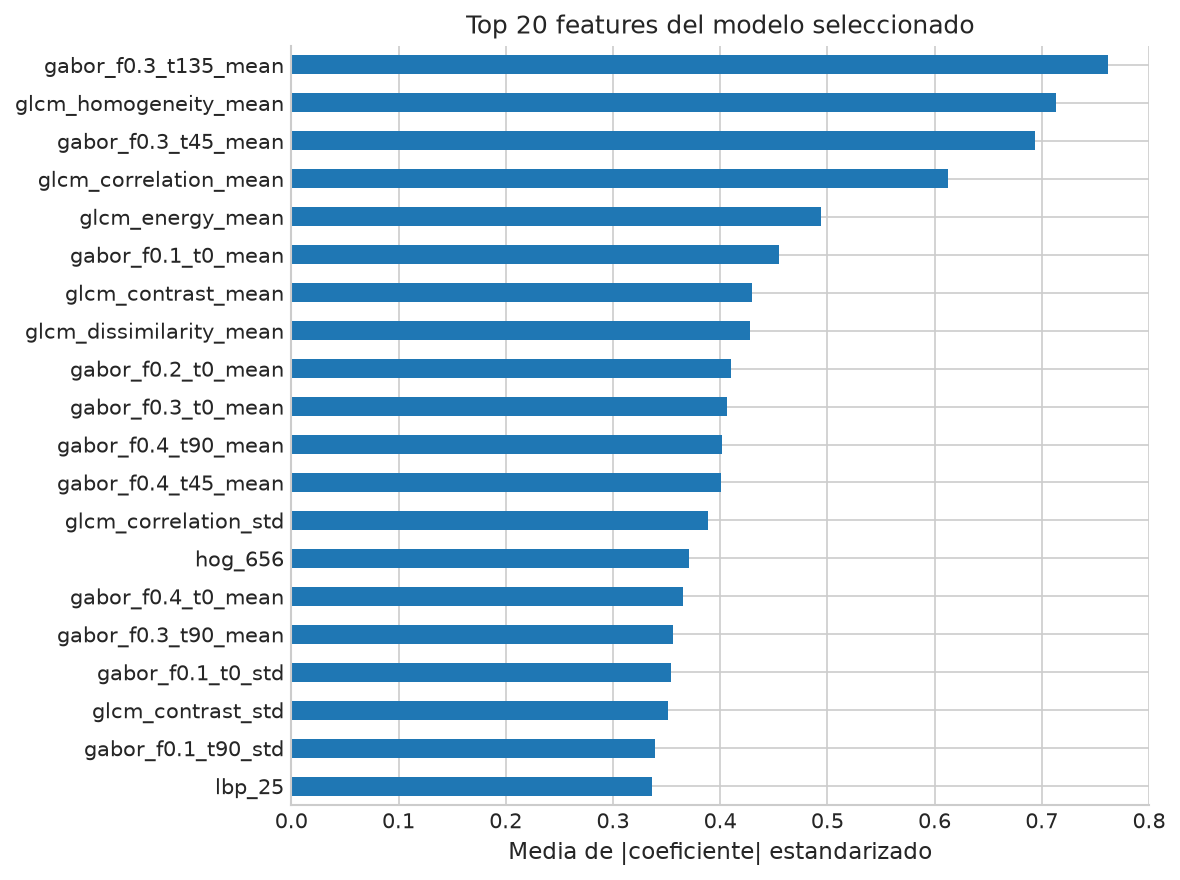

In [32]:
coef = clf.coef_
familias = {}
for familia, columnas in get_feature_groups(features_header).items():
    for col in columnas:
        familias[col] = familia

importancia = pd.DataFrame({
    'feature': sel_names,
    'mean_abs': np.abs(coef).mean(axis=0),
    'health': coef[clases.index(0)] if 0 in clases else np.nan,
    'sick': coef[clases.index(1)] if 1 in clases else np.nan,
    'tb': coef[idx_tb],
})
importancia['familia'] = importancia['feature'].map(familias).fillna('otra')
importancia.to_csv(REPORTS_DIR / '10_coeficientes.csv', index=False)

top = importancia.sort_values('mean_abs', ascending=False).head(20)
display(top.round(4).reset_index(drop=True))
por_familia = (
    importancia.groupby('familia')['mean_abs']
    .mean().sort_values(ascending=False).round(4)
)
display(por_familia.to_frame('mean_abs'))

fig, ax = plt.subplots(figsize=(8, 6))
top.iloc[::-1].plot.barh(x='feature', y='mean_abs', ax=ax, legend=False)
ax.set_xlabel('Media de |coeficiente| estandarizado')
ax.set_ylabel('')
ax.set_title('Top 20 features del modelo seleccionado')
fig.tight_layout()
fig.savefig(REPORTS_DIR / '10_coeficientes.png', dpi=220, bbox_inches='tight')
plt.show()


## 2. Coeficientes HOG por bloque


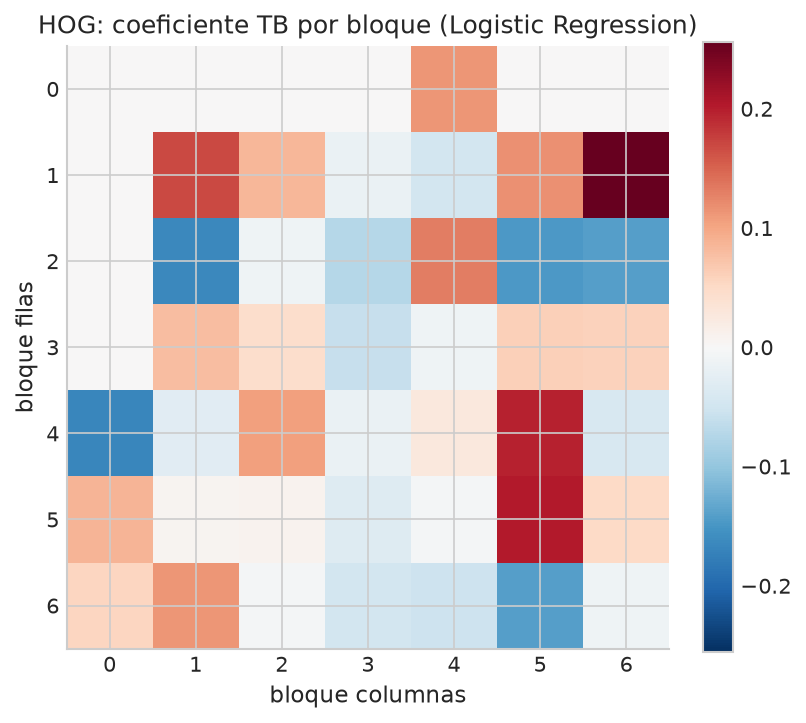

Features HOG seleccionadas: 248


In [33]:
hog = importancia[importancia['feature'].str.startswith('hog_')].copy()
grid = np.zeros((7, 7), dtype=float)
counts = np.zeros((7, 7), dtype=float)
for _, fila in hog.iterrows():
    idx = int(fila['feature'].split('_')[1])
    bloque = idx // 36
    br, bc = divmod(bloque, 7)
    grid[br, bc] += fila['tb']
    counts[br, bc] += 1
grid = np.divide(grid, counts, out=np.zeros_like(grid), where=counts > 0)

vmax = float(np.abs(grid).max()) if np.abs(grid).max() > 0 else 1.0
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(grid, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
ax.set_title(f'HOG: coeficiente TB por bloque ({seleccionado})')
ax.set_xlabel('bloque columnas')
ax.set_ylabel('bloque filas')
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(REPORTS_DIR / '10_hog_coeficientes.png', dpi=220, bbox_inches='tight')
plt.show()
print('Features HOG seleccionadas:', len(hog))


## 3. Ejemplos OOF


In [34]:
correctos = oof.index[(oof['y_true'] == 2) & (oof[seleccionado] == 2)].tolist()
errores = oof.index[(oof['y_true'] == 2) & (oof[seleccionado] != 2)].tolist()
ejemplos = correctos[:2] + errores[:1]
filas_ejemplo = []

for idx in ejemplos:
    x_sel = selector.transform(X_full[[idx]])
    x_scaled = scaler.transform(x_sel) if scaler is not None else x_sel
    contrib = x_scaled[0] * coef[idx_tb]
    orden = np.argsort(contrib)
    for pos in list(orden[:5]) + list(orden[-5:][::-1]):
        filas_ejemplo.append({
            'imagen': Path(meta.loc[idx, 'image_path']).name,
            'real': int(y_full[idx]),
            'pred': int(oof.loc[idx, seleccionado]),
            'feature': sel_names[pos],
            'contribucion_tb': float(contrib[pos]),
        })

tabla_ejemplo = pd.DataFrame(filas_ejemplo)
tabla_ejemplo.to_csv(REPORTS_DIR / '10_ejemplos_oof.csv', index=False)
display(tabla_ejemplo.round(4))


,imagen,real,pred,feature,contribucion_tb
0,tb0003.png,2,2,gabor_f0.1_t0_mean,-1.7308
1,tb0003.png,2,2,glcm_homogeneity_mean,-1.2834
2,tb0003.png,2,2,gabor_f0.4_t0_mean,-1.0054
3,tb0003.png,2,2,hog_1171,-0.8157
4,tb0003.png,2,2,hog_674,-0.7916
5,tb0003.png,2,2,gabor_f0.2_t0_mean,2.0646
6,tb0003.png,2,2,gabor_f0.3_t135_mean,1.5072
7,tb0003.png,2,2,gabor_f0.3_t0_mean,1.4971
8,tb0003.png,2,2,gabor_f0.3_t45_mean,1.2679
9,tb0003.png,2,2,lbp_13,0.8831


## 4. Oclusión y cajas de lesión

> Nota: esta celda reextrae features para cada celda de la cuadrícula 8×8; puede tardar varios minutos.


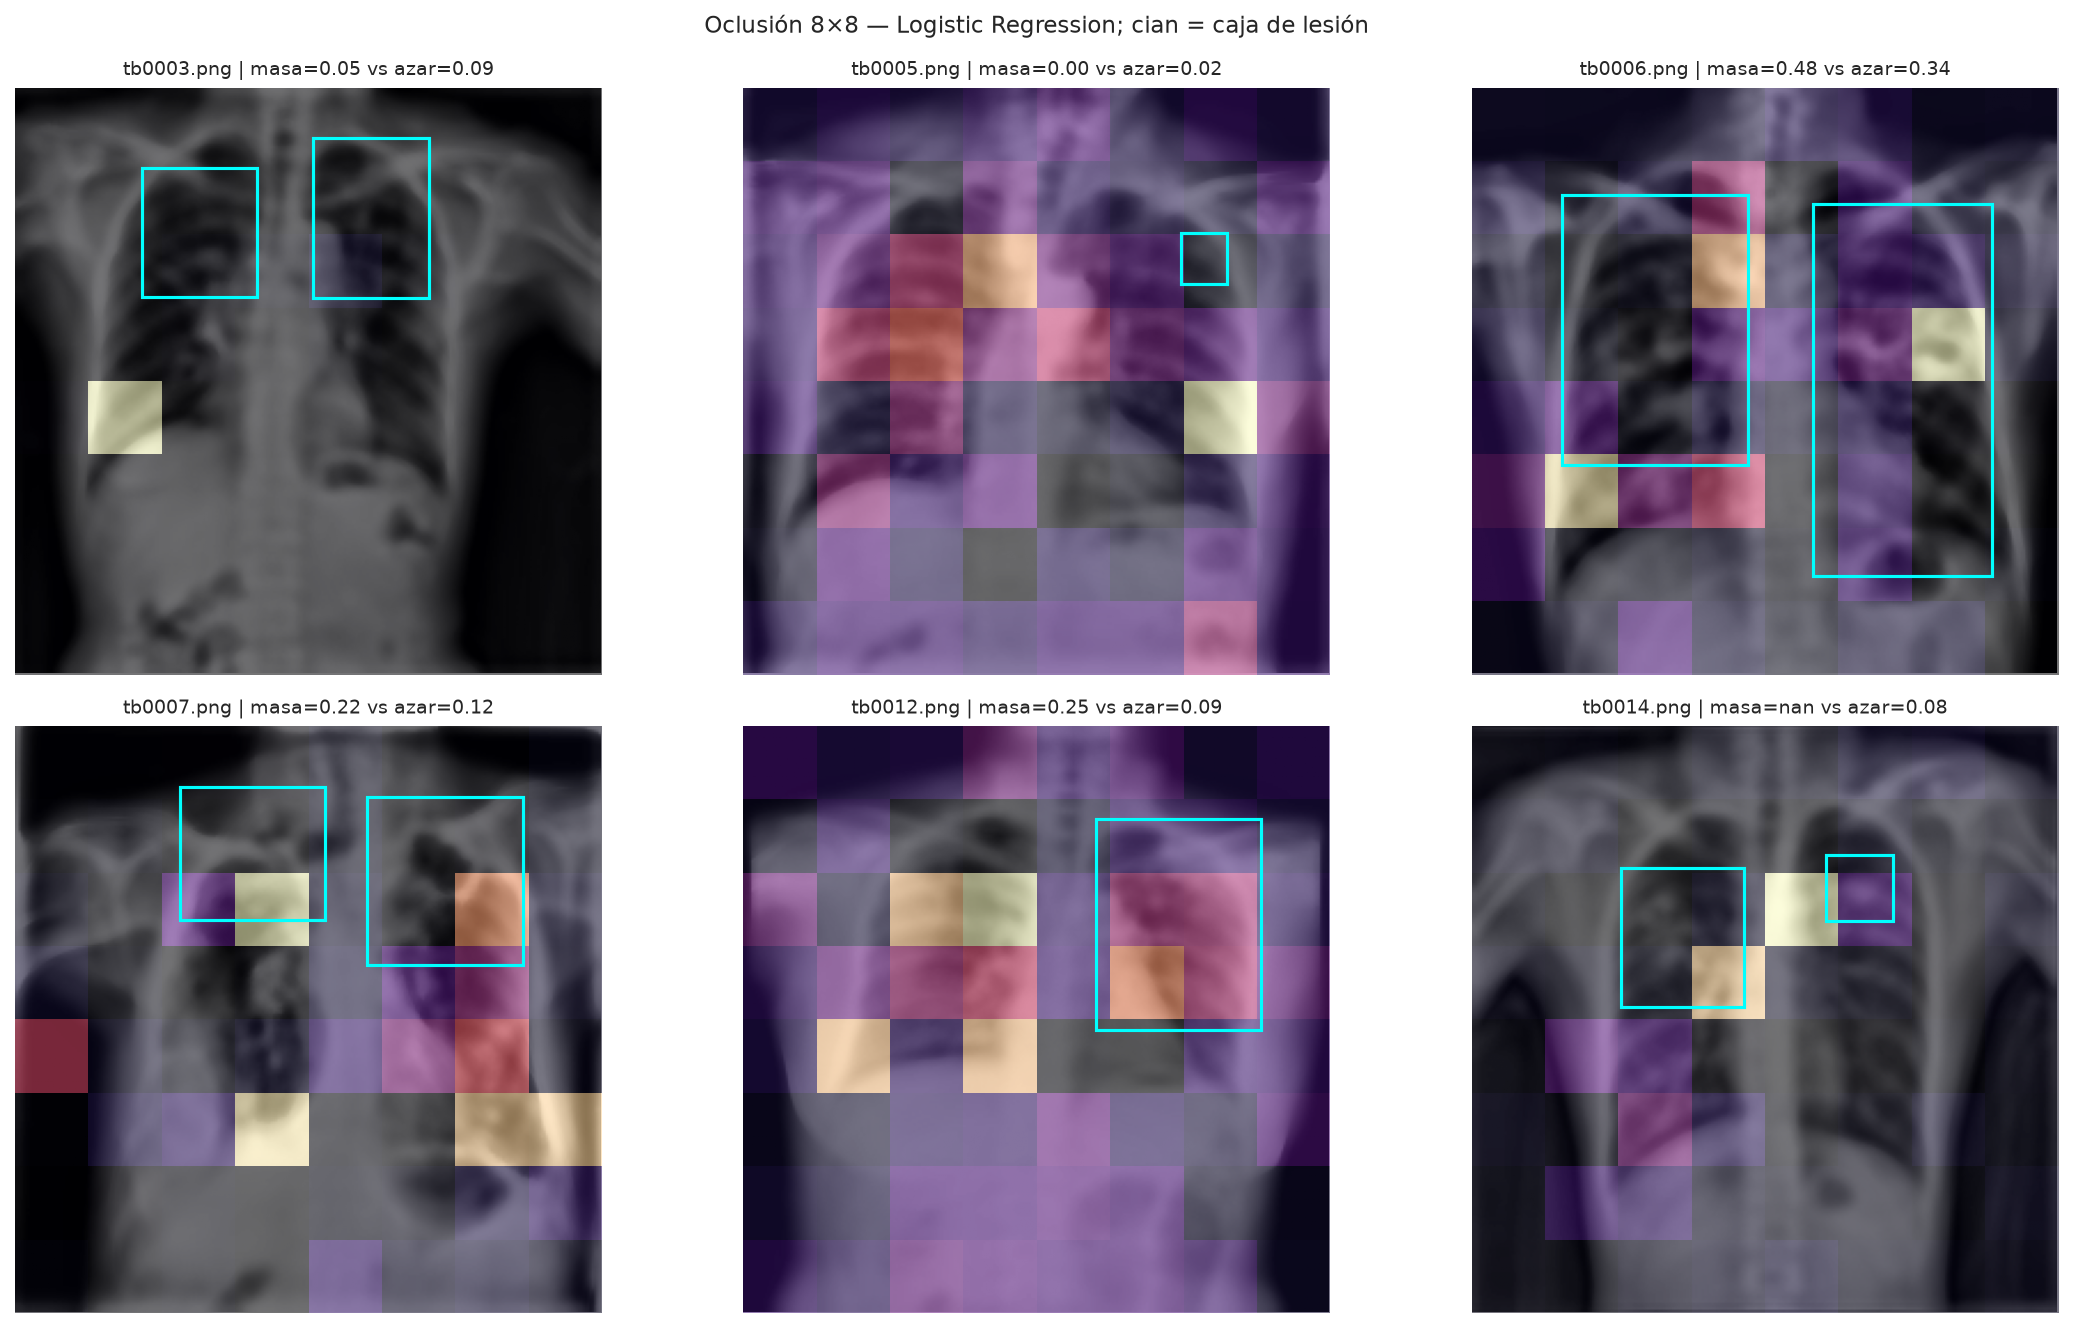

In [ ]:
coco_path = DATA_DIR / 'TBX11K' / 'annotations' / 'json' / 'TBX11K_trainval.json'
with open(coco_path, encoding='utf-8') as f:
    coco = json.load(f)

imagenes_coco = {img['id']: img['file_name'] for img in coco['images']}
basename_to_idx = {Path(p).name: i for i, p in enumerate(meta['image_path'])}
cajas = {}
for ann in coco['annotations']:
    file_name = imagenes_coco.get(ann['image_id'])
    if file_name is None:
        continue
    idx = basename_to_idx.get(Path(file_name).name)
    if idx is None:
        continue
    path = meta.loc[idx, 'image_path']
    cajas.setdefault(path, []).append(tuple(float(v) for v in ann['bbox']))

correctos = oof.index[(oof['y_true'] == 2) & (oof[seleccionado] == 2)]
paths_ok = set(meta.loc[correctos, 'image_path'])
candidatos = sorted(set(cajas) & paths_ok)
ejemplos = candidatos[:6]
if not ejemplos:
    raise ValueError('No hay imágenes TB correctas con caja.')

GRID = 8
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for ax, path in zip(axes, ejemplos):
    idx = int(meta.index[meta['image_path'] == path][0])
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue

    score_base = modelo.predict_proba(X_full[[idx]])[0, idx_tb]
    heatmap = np.zeros((GRID, GRID), dtype=float)
    h, w = img.shape
    cell_h, cell_w = h // GRID, w // GRID
    relleno = int(np.median(img))

    for gy in range(GRID):
        for gx in range(GRID):
            occ = img.copy()
            y0, y1 = gy * cell_h, (gy + 1) * cell_h
            x0, x1 = gx * cell_w, (gx + 1) * cell_w
            occ[y0:y1, x0:x1] = relleno

            with tempfile.NamedTemporaryFile(suffix='.png', delete=False) as tmp:
                tmp_path = tmp.name
            cv2.imwrite(tmp_path, occ)
            try:
                f = extract_features(tmp_path, 2, 'tb')
                vec = np.array([f[k] for k in feat_cols], dtype=np.float32).reshape(1, -1)
                score = modelo.predict_proba(vec)[0, idx_tb]
                heatmap[gy, gx] = score_base - score
            finally:
                Path(tmp_path).unlink(missing_ok=True)

    cajas_img = cajas[path]
    inside = total = 0.0
    celdas_caja = 0
    for gy in range(GRID):
        for gx in range(GRID):
            drop = max(heatmap[gy, gx], 0.0)
            total += drop
            cx = gx * cell_w + cell_w / 2
            cy = gy * cell_h + cell_h / 2
            if any(x <= cx <= x + bw and y <= cy <= y + bh
                   for x, y, bw, bh in cajas_img):
                inside += drop
                celdas_caja += 1
    fraccion = inside / total if total > 0 else float('nan')
    fraccion_azar = celdas_caja / (GRID * GRID)

    img_256 = preprocess(path, modo='full')
    ax.imshow(img_256, cmap='gray')
    ax.imshow(heatmap, extent=[0, 256, 256, 0], cmap='magma', alpha=0.55)
    for x, y, bw, bh in cajas_img:
        ax.add_patch(Rectangle((x * 0.5, y * 0.5), bw * 0.5, bh * 0.5,
                               fill=False, edgecolor='cyan', linewidth=1.5))
    ax.set_title(
        f'{Path(path).name} | masa={fraccion:.2f} vs azar={fraccion_azar:.2f}',
        fontsize=9,
    )
    ax.axis('off')

for ax in axes[len(ejemplos):]:
    ax.axis('off')
fig.suptitle(f'Oclusión 8×8 — {seleccionado}; cian = caja de lesión', fontsize=11)
fig.tight_layout()
fig.savefig(REPORTS_DIR / '10_oclusion_lesiones.png', dpi=300, bbox_inches='tight')
plt.show()


## Conclusiones

- La interpretación corresponde al modelo seleccionado por la CV, no a un
  modelo fijo.
- Los coeficientes son asociaciones condicionadas al modelo y al selector;
  no son evidencia causal.
- El mapa HOG y la oclusión son exploratorios. La comparación de `masa` frente
  a `azar` da una referencia mínima, pero no sustituye una localización
  validada.
- Las explicaciones describen el comportamiento del modelo y no constituyen
  una validación clínica.
